### Ecuación del Calor en 1D & 2D

Según Wikipedia; "La ecuación del calor es una importante ecuación diferencial en derivadas parciales que describe la distribución del calor (o variaciones de la temperatura) en una región a lo largo del transcurso del tiempo."

$$ \frac{\partial T}{\partial t} = \alpha \nabla^2 T$$

Para un sistema de de tres variables $(x, y, z) \in \mathbb{R}^3$ y de la variable temporal $t$ toma la siguiente forma

$$ \frac{\partial T}{\partial t} = \alpha \left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}+\frac{\partial^2 T}{\partial z^2}\right)$$

Donde:

- T es la Temperatura.
- $\alpha$ es la difusividad termica del material.

En esta ocación, este Notebook tiene como finalidad resolver la Ec. del Calor en 1D & 2D. 
Por lo que (como ya es costumbre) comenzaremos importando las librerias necesarias.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from IPython.display import display, clear_output 

### Ecuación del Calor en 1D

Al solo considerar una dimension espacial ($x$) en la propagación del calor la ecuación se convierte en

$$ \frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}$$

Para resolver la ecuación, se utilizará el método de diferencias finitas, el cual consiste en discretizar el dominio de la función y las derivadas en puntos finitos dentro de ese dominio. En el caso de 1D, la divición del dominio quedaría de la siguiente forma

<center><img src=DiferenciasFinitas1D.png width="250" class='center'></center>

Y la aproximación de la derivada finalmente sería

$$\frac{\partial T}{\partial t} \approx \frac{T^{n+1}_{i}-T^{n}_{i}}{\Delta t} \approx \alpha \frac{T^{n}_{i+1}-2T^{n}_{i}+T^{n}_{i-1}}{\Delta x^2}$$

(La deducción completa de esta aproximación está en la parte de Anexos de este Notebook)

Donde: 
-  n es el instante de tiempo presente.
-  n+1 es el instante de tiempo futuro.

Se comienza declarando las constantes.

In [3]:
# constantes
alpha = 113 #mm2 / s
nodes = 40
L = 50 #mm
t = 3 #s
To = 20 # °C

# diferenciales
dx = L / nodes
dt = 0.5 * dx**2 / alpha
t_nodes = int(t / dt)

# temperatura inicial de los nodos
T = np.zeros(nodes) + To

# condiciones de frontera
T[0] = 100
T[-1] = 20

# configurar el gráfico
fig, axis = plt.subplots(figsize=(10,1))
mesh = axis.pcolormesh([T], cmap=plt.cm.jet, vmin=0, vmax=100)
plt.colorbar(mesh, ax=axis, orientation='horizontal', pad=0.5)

# tiempo inicial real
start_time = time.time()

# simulación
counter = 0

while counter < t:
    w = T.copy()
    for i in range(1, nodes-1):
        T[i] = alpha * ((w[i - 1] - 2*w[i] + w[i + 1]) / dx**2) * dt +w[i]

    counter += dt

    # actualizar el grafico
    mesh.set_array(T)
    axis.set_title(f'Tiempo transcurrido de simulación: {counter:.2f}')
    clear_output(wait=True)
    display(fig)

# temperatura individual por nodo
T_per_node = np.round(T, decimals=2)

# cerrar el gráfico final
plt.close()

# tiempo real total
end_time = time.time()
print(f'El tiempo que tardo la simulación en correr es: {end_time - start_time:.2f} segundos')

# resumen de resultados
print(f'Tiempo: {counter:.2f} s, \nTemperatura promedio: {np.average(T):.2f}°C\n')
print(f'La temperatura de cada nodo es: {T_per_node}')

SyntaxError: '[' was never closed (1459414485.py, line 17)

___

### Ecuación del Calor en 2D

Al considerar dos dimensiones espaciales ($x,y$) en la propagación del calor la ecuación se convierte en

$$ \frac{\partial T}{\partial t} = \alpha \left(\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2}\right)$$

En el caso de 2D, la divición del dominio quedaría de la siguiente forma

<center><img src=DiferenciasFinitas2D.png width="280" class='center'></center>

Y la aproximación de la derivada finalmente sería

$$\frac{\partial T}{\partial t} \approx \frac{T^{n+1}_{i}-T^{n}_{i}}{\Delta t} \approx \alpha \left(\frac{T^{n}_{i+1}-2T^{n}_{i}+T^{n}_{i-1}}{\Delta x^2} + \frac{T^{n}_{j+1}-2T^{n}_{j}+T^{n}_{j-1}}{\Delta y^2}\right)$$

(La deducción completa de esta aproximación está en la parte de Anexos de este Notebook).

Se comienza de igual forma, declarando las constantes.

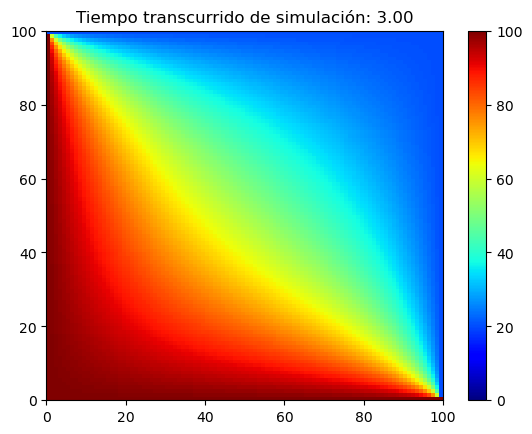

El tiempo que tardo la simulación en correr es: 920.27 segundos
Tiempo: 3.00 s, 
Temperatura promedio: 58.32°C

La temperatura de cada nodo es: [[100.   100.   100.   ... 100.   100.   100.  ]
 [100.    99.98  99.96 ...  75.8   60.    20.  ]
 [100.    99.96  99.91 ...  59.98  44.18  20.  ]
 ...
 [100.    75.8   59.98 ...  20.05  20.03  20.  ]
 [100.    60.    44.18 ...  20.03  20.01  20.  ]
 [ 20.    20.    20.   ...  20.    20.    20.  ]]


In [6]:
# constantes
alpha = 113 #mm2 / s
nodes = 100
L = 50 #mm
t = 3 #s
To = 20 # °C

# diferenciales
dx = L / nodes
dy = L / nodes
dt =  min(dx**2 / (4 * alpha), dy**2 / (4 * alpha))
t_nodes = int(t / dt)

# temperatura inicial
T = np.zeros((nodes, nodes)) + To

# condiciones de frontera
T[:, 0] = 100
T[:, -1] = 20
T[0, :] = 100
T[-1, :] = 20

# configurar el gráfico
fig, axis = plt.subplots()
mesh = axis.pcolormesh(T, cmap=plt.cm.jet, vmin=0, vmax=100)
plt.colorbar(mesh, ax=axis)

# tiempo inicial real
start_time = time.time()

# simulación
counter = 0

while counter < t:
    w = T.copy()

    for i in range(1, nodes-1):
        for j in range(1, nodes-1):
            ddTx = (w[i - 1, j] - 2*w[i, j] + w[i + 1, j]) / dx**2
            ddTy = (w[i, j - 1] - 2 * w[i, j] + w[i, j + 1]) / dy**2
            T[i, j] = alpha * (ddTx + ddTy) * dt +w[i, j]

    counter += dt

    # actualizar el grafico
    mesh.set_array(T.ravel())
    axis.set_title(f'Tiempo transcurrido de simulación: {counter:.2f}')
    clear_output(wait=True)
    display(fig)

# temperatura individual por nodo
T_per_node = np.round(T, decimals=2)

# cerrar el gráfico final
plt.close()

# tiempo real total
end_time = time.time()
print(f'El tiempo que tardo la simulación en correr es: {end_time - start_time:.2f} segundos')

# resumen de resultados
print(f'Tiempo: {counter:.2f} s, \nTemperatura promedio: {np.average(T):.2f}°C\n')
print(f'La temperatura de cada nodo es: {T_per_node}')

___

### Anexos
#### 1.- Deducción de las Aproximaciones de las Ecuaciones Diferencias

Para resolver la ecuación, se utilizará el método de diferencias finitas, el cual consiste en discretizar el dominio de la función y las derivadas en puntos finitos dentro de ese dominio. En el caso de 1D, la divición del dominio quedaría de la siguiente forma

<center><img src=DiferenciasFinitas1D.png width="250" class='center'></center>

Partiendo de esta aproximación de una derivada:

$$ \frac{dy}{dx} \approx \frac{\Delta y}{\Delta x} \approx \frac{y_{2}-y_{1}}{x_{2}-x_{1}}$$

Se define la derivada en cada punto de $i$

$$\frac{\partial T}{\partial x_{i+1}} \approx \frac{T_{i+1}-T_{i}}{\Delta x}$$

$$\frac{\partial T}{\partial x_{i-1}} \approx \frac{T_{i}-T_{i-1}}{\Delta x}$$

$$\frac{\partial^2 T}{\partial x^2} \approx
\frac{
\displaystyle\frac{\partial T}{\partial x_{i+1}}-
\displaystyle\frac{\partial T}{\partial x_{i-1}}
} {\Delta x}
\approx\frac{\displaystyle\frac{T_{i+1}-T_{i}-T_{i}+T_{i-1}}{\Delta x}}{\Delta x}$$

$$\frac{\partial^2 T}{\partial x^2} 
\approx \frac{T^{n}_{i+1}-2T^{n}_{i}+T^{n}_{i-1}}{\Delta x^2}$$

Mientras que para una diferencia de tiempo $t$

$$\frac{\partial T}{\partial t} \approx \frac{T^{n+1}_{i}-T^{n}_{i}}{\Delta t}$$

Donde $n$ es el instante de tiempo presente mientras que $n+1$ es un instante en un tiempo futuro. Finalmente, la aproximación de la ecuación en 1D es

$$ \boxed{
\frac{T^{n+1}_{i}-T^{n}_{i}}{\Delta t} \approx \frac{T^{n}_{i+1}-2T^{n}_{i}+T^{n}_{i-1}}{\Delta x^2}}$$


Para 2D la división del dominio queda de la siguiente forma

<center><img src=DiferenciasFinitas2D.png width="270" class='center'></center>

Donde $$\Delta x = \Delta y$$

El proceso de obtención de la aproximación de la derivada parcial con respecto de $y$ es igual al de $x$, por lo que finalmente se tendría

$$\frac{\partial^2 T}{\partial y^2} 
\approx \frac{T^{n}_{j+1}-2T^{n}_{j}+T^{n}_{j-1}}{\Delta y^2}$$

$$ \boxed{
\frac{T^{n+1}_{j}-T^{n}_{j}}{\Delta t} \approx \frac{T^{n}_{j+1}-2T^{n}_{j}+T^{n}_{j-1}}{\Delta y^2}}$$

Al considerar dos dimensiones espaciales ($x,y$) en la propagación del calor la ecuación se convierte en

$$ \frac{\partial T}{\partial t} = \alpha \left(\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2}\right)$$


Sustituyendo finalmente tendríamos la aproximación en diferencias finitas en 2D

$$\boxed{
\frac{\partial T}{\partial t} \approx \frac{T^{n+1}_{i}-T^{n}_{i}}{\Delta t} \approx \alpha \left(\frac{T^{n}_{i+1}-2T^{n}_{i}+T^{n}_{i-1}}{\Delta x^2} + \frac{T^{n}_{j+1}-2T^{n}_{j}+T^{n}_{j-1}}{\Delta y^2}\right)}$$

Esta ecuación es mas que suficiente para describir el fenomeno de una forma algebraica, y, de hecho es la utilizada en este Notebook para resolver el ejercicio, sin embargo, existe otra forma de la ecuación mas condensada. 

Si tomamos un escenario de estado estacionario la Ec. se reduciría a 

$$\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} = 0$$

Tomando de nuevo en cuenta que $\Delta x = \Delta y$, sustituyendo por las aproximaciones, se tendría

$$\frac{T_{i+1,j}+T_{i-1,j}-2T_{i,j}+T_{i,j+1}+T_{i,j-1}-2T_{i,j}}{(\Delta x)^2} = 0$$

$$T_{i+1,j}+T_{i-1,j}-2T_{i,j}+T_{i,j+1}+T_{i,j-1}-2T_{i,j} = 0$$

$$\boxed{T_{i+1,j}+T_{i-1,j}+T_{i,j+1}+T_{i,j-1}-4T_{i,j} = 0}$$

Lo cual ha reducido la Ec. Diferencial a una Ec. algebraica. A partir de este punto se pueden proponer otro tipo de estrategias de solución, como formar un sistema de ecuaciones lineales.

#### 2.- Deducción de la Aproximación del Diferencial de Tiempo

Para que la solución pueda converger, se tiene que utilizar la condicion de Courant-Friedrichs-Lewy (CFL), esta condición establece una relación entre el tamaño de paso de tiempo y el tamaño espacial para garantizar la estabilidad de la solución numérica. En el caso que nos consierne, para la Ec. de Calor en 1D la condicion de CFL se expresa como:

$$\Delta t \leq \frac{\Delta x^2}{2\alpha}$$

En 2D, como esttamos utilizando una malla rectangular con pasos de discretización $\Delta x$ en dirección $x$ y $\Delta y$ en dirección $y$ la condición CFL puede expresarse como

$$\Delta t \leq \frac{\Delta x^2 + \Delta y^2}{4\alpha}$$

Esta expresión asegura que el paso de tiempo $\Delta t$ sea lo suficientemente pequeño para garantizar la estabilidad numérica en ambas direcciones espaciales.